# carbon-geo-mcp: demo on synthetic data

**Question:** can an AI assistant be trusted with the routine spatial checks of a carbon project audit if it calls real GIS tools instead of guessing?

This notebook does what an AI host does: it **starts the MCP server, lists its tools and calls them** through the official MCP Python client. Then it **confirms the key numbers with an independent GeoPandas script**, in a different equal-area CRS.

The sample data is **fictional**: an 8,000 ha project in the Paraguayan Chaco, delivered in EPSG:4326, with problems planted on purpose.

## 0. Setup

In Colab this installs the server from GitHub and clones the repository for the sample data. Locally it uses the installed package.

In [1]:
import os, sys, subprocess, json

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/albertolozada/carbon-geo-mcp.git"], check=True)
    if not os.path.exists("carbon-geo-mcp"):
        subprocess.run(["git", "clone", "-q", "https://github.com/albertolozada/carbon-geo-mcp.git"], check=True)
    os.chdir("carbon-geo-mcp")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

SAMPLE = os.path.abspath("data/sample")
print("Sample data:", sorted(os.listdir(SAMPLE)))

Sample data: ['lossyear_sample.tif', 'plots.gpkg', 'project_strata.gpkg', 'protected_area.gpkg']


## 1. Start the server and list its tools

The server is launched as a subprocess over stdio, exactly as Claude Desktop or Cursor would launch it.

In [2]:
import pandas as pd
from mcp import Client, StdioServerParameters

SERVER = StdioServerParameters(command=sys.executable, args=["-m", "carbon_geo_mcp.server"])

async def call(tool, **args):
    """Call one tool through a real MCP client and return its structured result."""
    async with Client(SERVER) as client:
        res = await client.call_tool(tool, args)
    if res.is_error:
        raise RuntimeError(res.content[0].text)
    return res.structured_content

async with Client(SERVER) as client:
    tools = (await client.list_tools()).tools
pd.DataFrame([{"tool": t.name, "read_only": t.annotations.read_only_hint,
               "description": t.description.split(".")[0]} for t in tools])

,tool,read_only,description
0,layer_info,True,Describe a vector layer before any analysis: C...
1,area_by_stratum,True,"Area in hectares of a polygon layer, in total ..."
2,compare_declared_area,True,Compare areas declared in a project document (...
3,check_overlap,True,Overlap between two polygon layers (e
4,plots_in_strata,True,Check monitoring or inventory plots against th...
5,forest_loss_in_area,True,Forest loss per year inside an area of interes...
6,data_completeness,True,Completeness of the attributes of a layer: fil...
7,plan_crs,True,Reflect on the coordinate systems BEFORE measu...
8,check_raster_availability,True,Check which satellite images exist over an are...
9,create_map,True,Draw a quick check map of up to 6 layers (poly...


## 2. Plan the CRS before measuring

First the agent reflects on the coordinate systems: where the layers fall, their CRS and datum, and which CRS to use for areas and distances.

In [3]:
plan = await call("plan_crs", paths=[f"{SAMPLE}/project_strata.gpkg", f"{SAMPLE}/plots.gpkg", f"{SAMPLE}/protected_area.gpkg"])
print("Areas:", plan["proposal"]["areas"]["why"])
print("Distances:", plan["proposal"]["distances"]["crs"], "-", plan["proposal"]["distances"]["why"])
print("UTM area distortion at the edge:", plan["proposal"]["utm_area_distortion_at_edge_pct"], "%")
print("Warnings:", plan["warnings"] or "none")
pd.DataFrame(plan["layers"])[["file", "crs", "datum", "features", "utm_zones", "coordinate_problems"]]

Areas: Lambert Azimuthal Equal Area centred on the data preserves areas exactly at any latitude.
Distances: EPSG:32720 - UTM zone 20 contains the centre of the data; distance error at project scale is negligible.
UTM area distortion at the edge: -0.049 %
Warnings: none


,file,crs,datum,features,utm_zones,coordinate_problems
0,project_strata.gpkg,EPSG:4326,World Geodetic System 1984 ensemble,3,[20],[]
1,plots.gpkg,EPSG:4326,World Geodetic System 1984 ensemble,40,[20],[]
2,protected_area.gpkg,EPSG:4326,World Geodetic System 1984 ensemble,1,[20],[]


## 3. Look at the layers first

In [4]:
info = await call("layer_info", path=f"{SAMPLE}/project_strata.gpkg")
{k: info[k] for k in ["crs", "is_geographic", "units", "features", "invalid_geometries", "warnings"]}

{'crs': 'EPSG:4326',
 'is_geographic': True,
 'units': 'degree',
 'features': 3,
 'invalid_geometries': 0,
 'warnings': ['Geographic CRS (degrees): areas, distances and buffers must not be computed in this CRS.']}

The layer is in degrees. An area computed directly on these coordinates would be meaningless, so the tools reproject before measuring and say which CRS they used.

## 4. Area by stratum and declared areas

In [5]:
area = await call("area_by_stratum", path=f"{SAMPLE}/project_strata.gpkg", stratum_field="stratum")
print("CRS used:", area["crs_choice"])
print("Total (dissolved):", area["total_area_ha"], "ha | sum of strata:", area["sum_of_strata_ha"],
      "ha | overlap between strata:", area["overlap_between_strata_ha"], "ha")
pd.DataFrame(area["strata"])

CRS used: local Lambert Azimuthal Equal Area centred on the data (equal-area)
Total (dissolved): 8004.22 ha | sum of strata: 8054.24 ha | overlap between strata: 50.02 ha


,stratum,features,area_ha,sum_of_feature_areas_ha,internal_overlap_ha
0,dense_forest,1,4802.58,4802.58,0.0
1,non_forest,1,400.20,400.20,0.0
2,open_forest,1,2851.46,2851.46,0.0


In [6]:
declared = {"total": 8000, "dense_forest": 4800, "open_forest": 2800, "non_forest": 400}
cmp = await call("compare_declared_area", path=f"{SAMPLE}/project_strata.gpkg",
                 declared_ha=declared, stratum_field="stratum", tolerance_pct=1.0)
pd.DataFrame(cmp["comparison"])

,item,declared_ha,calculated_ha,difference_ha,difference_pct,status
0,total,8000.0,8004.22,4.22,0.053,within tolerance
1,dense_forest,4800.0,4802.58,2.58,0.054,within tolerance
2,open_forest,2800.0,2851.46,51.46,1.838,outside tolerance
3,non_forest,400.0,400.20,0.20,0.050,within tolerance


## 5. Overlap with a protected area

In [7]:
ovl = await call("check_overlap", path_a=f"{SAMPLE}/project_strata.gpkg", path_b=f"{SAMPLE}/protected_area.gpkg",
                 id_field_a="stratum", id_field_b="pa_name")
print(ovl["message"], f"{ovl['overlap_ha']} ha = {ovl['overlap_pct_of_a']} % of the project")
pd.DataFrame(ovl["overlapping_pairs"])

The layers overlap. 150.08 ha = 1.875 % of the project


,id_a,id_b,overlap_ha
0,open_forest,Fictional Reserve,150.08


## 6. Monitoring plots

In [8]:
pl = await call("plots_in_strata", plots_path=f"{SAMPLE}/plots.gpkg", strata_path=f"{SAMPLE}/project_strata.gpkg",
                stratum_field="stratum", plot_stratum_field="stratum", plot_id_field="plot_id", edge_distance_m=50)
print(f"{pl['plots_inside']} of {pl['plots_total']} plots inside the strata. Distances in {pl['crs_used']}.")
for key in ["outside", "stratum_mismatches", "plots_near_boundary", "duplicate_coordinates"]:
    print(f"{key}: {pl[key]}")

38 of 40 plots inside the strata. Distances in EPSG:32720.
outside: [{'plot': 'P90', 'distance_to_strata_m': 300.0}, {'plot': 'P91', 'distance_to_strata_m': 800.0}]
stratum_mismatches: [{'plot': 'P92', 'declared_stratum': 'dense_forest', 'spatial_stratum': ['open_forest']}]
plots_near_boundary: [{'plot': 'P93', 'distance_to_boundary_m': 20.0}]
duplicate_coordinates: ['P01', 'P94']


## 7. Forest loss in the monitoring period

In [9]:
loss = await call("forest_loss_in_area", aoi_path=f"{SAMPLE}/project_strata.gpkg",
                  lossyear_raster=f"{SAMPLE}/lossyear_sample.tif", start_year=2015, end_year=2024)
print(f"Total loss {loss['period']}: {loss['total_loss_ha']} ha ({loss['loss_pct_of_aoi']} % of the area)")
print("Pixel area:", loss["pixel_area_method"], "| raster coverage:", loss["raster_coverage_pct"], "%")
pd.DataFrame(loss["loss_by_year"])

Total loss 2015-2024: 288.95 ha (3.61 % of the area)
Pixel area: geodesic area per row (WGS84 ellipsoid) | raster coverage: 100.0 %


,year,pixels,loss_ha
0,2015,280,20.08
1,2016,410,29.40
2,2017,137,9.83
3,2018,463,33.20
4,2019,207,14.85
5,2020,347,24.89
6,2021,427,30.62
7,2022,675,48.41
8,2023,539,38.66
9,2024,544,39.01


## 8. Imagery available for the next analysis

Before planning an NDVI analysis, check which Sentinel-2 dates fully cover the project with little cloud. Only the bounding box and the dates are sent to the STAC catalog. **This cell needs internet access** (it runs in Colab).

In [ ]:
try:
    av = await call("check_raster_availability", aoi_path=f"{SAMPLE}/project_strata.gpkg",
                    start_date="2024-06-01", end_date="2024-09-30", max_cloud_pct=20)
    print(f"{av['scenes_found']} scenes on {av['acquisition_dates']} dates; usable dates: {av['usable_dates_count']}")
    print("Sent to the catalog:", av["sent_to_catalog"])
    display(pd.DataFrame(av["best_dates"]))
except RuntimeError as exc:
    print("Catalog not reachable from this environment:", exc)

## 9. Attribute completeness

In [11]:
comp = await call("data_completeness", path=f"{SAMPLE}/plots.gpkg")
pd.DataFrame(comp["fields"])

,field,filled,missing,filled_pct,distinct_values
0,plot_id,40,0,100.0,40
1,stratum,40,0,100.0,3


## 10. The script confirms

The agent explores; a script confirms. Here the key numbers are recomputed **without the server**, with plain GeoPandas and Rasterio, using a *different* equal-area CRS (EPSG:6933, World Cylindrical Equal Area) and a different pixel-area formula. Small differences are expected from the projection; large ones would mean a bug.

In [12]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterio.mask import mask

EA = "EPSG:6933"
strata = gpd.read_file(f"{SAMPLE}/project_strata.gpkg").to_crs(EA)
pa = gpd.read_file(f"{SAMPLE}/protected_area.gpkg").to_crs(EA)

total = strata.union_all().area / 1e4
overlap_strata = strata.area.sum() / 1e4 - total
overlap_pa = strata.union_all().intersection(pa.union_all()).area / 1e4

with rasterio.open(f"{SAMPLE}/lossyear_sample.tif") as src:
    aoi = gpd.read_file(f"{SAMPLE}/project_strata.gpkg").to_crs(src.crs).union_all()
    arr, tr = mask(src, [aoi], crop=True, filled=False)
band = arr[0]
rows = np.arange(band.shape[0])
lat = tr.f + (rows + 0.5) * tr.e                       # pixel-centre latitude per row
pix = (tr.a * 111_320 * np.cos(np.radians(lat))) * (abs(tr.e) * 110_574)  # simple spherical approximation
lossmask = (~np.ma.getmaskarray(band)) & (np.ma.getdata(band) >= 15) & (np.ma.getdata(band) <= 24)
loss_check = (lossmask * pix[:, None]).sum() / 1e4

check = pd.DataFrame([
    ["Project area (ha)", area["total_area_ha"], total],
    ["Overlap between strata (ha)", area["overlap_between_strata_ha"], overlap_strata],
    ["Overlap with protected area (ha)", ovl["overlap_ha"], overlap_pa],
    ["Forest loss 2015-2024 (ha)", loss["total_loss_ha"], loss_check],
], columns=["check", "carbon-geo-mcp", "independent script"])
check["difference_pct"] = ((check["carbon-geo-mcp"] - check["independent script"]) / check["independent script"] * 100).round(3)
check.round(2)

,check,carbon-geo-mcp,independent script,difference_pct
0,Project area (ha),8004.22,8004.22,-0.00
1,Overlap between strata (ha),50.02,50.03,-0.01
2,Overlap with protected area (ha),150.08,150.08,0.00
3,Forest loss 2015-2024 (ha),288.95,288.42,0.18


## 11. Check map

`create_map` returns the map as an image inside the tool result: the agent can show the layers behind a finding without writing any file.

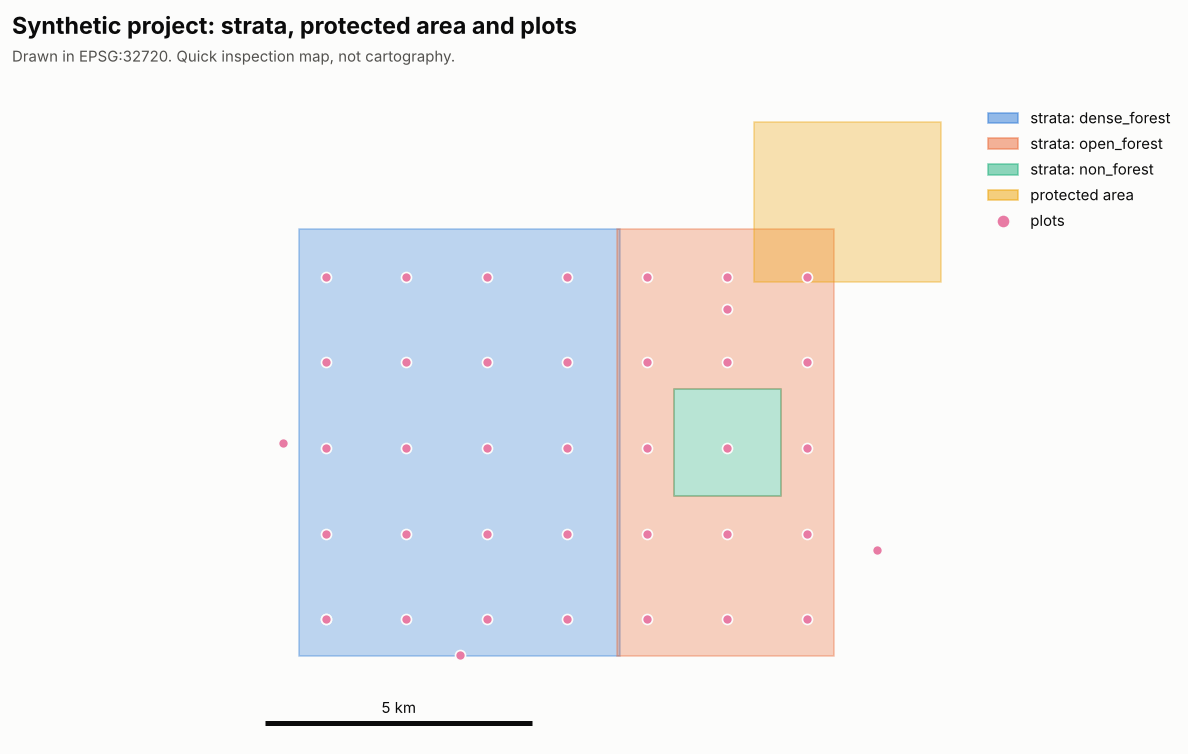

In [13]:
import base64
from IPython.display import Image

async with Client(SERVER) as client:
    res = await client.call_tool("create_map", {
        "layers": [
            {"path": f"{SAMPLE}/project_strata.gpkg", "category_field": "stratum", "label": "strata"},
            {"path": f"{SAMPLE}/protected_area.gpkg", "label": "protected area"},
            {"path": f"{SAMPLE}/plots.gpkg", "label": "plots"},
        ],
        "title": "Synthetic project: strata, protected area and plots",
    })
Image(data=base64.b64decode(res.content[0].data), width=850)

## 12. Conclusions

- The agent planned the CRS first, and `plan_crs` predicted the 0.05 % UTM distortion before any area was measured.
- Every number came from a tool call, and every tool call said which CRS it used.
- The planted problems were all found: 50 ha of overlapping strata, a declared area 1.8 % off, 150 ha inside a protected area, plots outside or in the wrong stratum, and the forest loss of the period.
- The independent script agrees with the tools within the expected projection differences.

**Limitations:** synthetic data; forest loss counts pixels whose centre falls inside the area.